# FairBatch on Adult, German and COMPAS
Evaluation of FairBatch (Roh et al., ICLR 2021) targeting demographic parity. The code lives in `fairness_eval/` and the settings in `fairness_eval/config.py`. Results are cached in `results/`; delete a CSV to rerun that experiment.

In [1]:
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon

from fairness_eval import config as cfg, data, experiments as ex

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Datasets
`z = 1` is the privileged group. `base_rate` is the share of favorable labels (income above 50K, good credit, no recidivism within two years).

In [2]:
data.summary()

,dataset,rows,features,sensitive,share_privileged,base_rate,base_rate_z0,base_rate_z1
0,adult,45222,80,sex (male = 1),0.675,0.248,0.114,0.312
1,german,1000,48,age (older than 25 = 1),0.810,0.700,0.579,0.728
2,compas,5278,10,"race (Caucasian = 1, African-American = 0)",0.398,0.530,0.477,0.609


## 2. Fairness of the original labels
Computed on the full dataset before any split or model. DP_Diff = P(y=1 | z=0) − P(y=1 | z=1), DIR = P(y=1 | z=0) / P(y=1 | z=1), consistency = 1 − mean |y_i − mean label of the 5 nearest neighbours of i| on standardized features.

In [3]:
original = ex.original_fairness()
original

,dataset,dp_diff,dir,consistency
0,adult,-0.199,0.363,0.796
1,german,-0.149,0.795,0.658
2,compas,-0.132,0.783,0.619


## 3. Settings
Logistic regression (the authors' `models.py`), Adam, stratified 70/30 split on label and group, features standardized on the training set, 10 seeds. The baseline uses uniform minibatches of the same size; FairBatch uses `target_fairness="dp"`. `alpha` is the step size of the lambda updates.

In [4]:
pd.DataFrame(cfg.TRAIN).T

,batch_size,epochs,lr,alpha
adult,500.0,100.0,0.005,0.005
german,50.0,300.0,0.005,0.005
compas,100.0,200.0,0.005,0.005


## 4. Before and after mitigation
Held out test set, mean and std over 10 seeds. `test_labels` are the true labels of the test set, `baseline` and `fairbatch` are model predictions.

In [5]:
main = ex.main_experiment()
ex.summary(main)

dp_diff           dir        consistency        accuracy  \
                       mean    std   mean    std        mean    std     mean   
dataset method                                                                 
adult   test_labels  -0.199  0.000  0.364  0.000       0.784  0.002    1.000   
        baseline     -0.185  0.006  0.295  0.017       0.932  0.002    0.845   
        fairbatch    -0.030  0.023  0.867  0.102       0.926  0.001    0.829   
german  test_labels  -0.149  0.000  0.795  0.000       0.642  0.015    1.000   
        baseline     -0.156  0.051  0.798  0.070       0.727  0.021    0.760   
        fairbatch    -0.036  0.054  0.953  0.070       0.738  0.025    0.745   
compas  test_labels  -0.132  0.000  0.783  0.000       0.610  0.009    1.000   
        baseline     -0.276  0.018  0.627  0.022       0.948  0.004    0.673   
        fairbatch     0.132  0.034  1.224  0.061       0.931  0.007    0.638   

                           balanced_accuracy         
                       std              mean    std  
dataset method                                       
adult   test_labels  0.000             1.000  0.000  
        baseline     0.001             0.761  0.005  
        fairbatch    0.004             0.744  0.008  
german  test_labels  0.000             1.000  0.000  
        baseline     0.016             0.692  0.028  
        fairbatch    0.020             0.668  0.029  
compas  test_labels  0.000             1.000  0.000  
        baseline     0.006             0.670  0.006  
        fairbatch    0.008             0.629  0.009

In [6]:
# before: original labels on the full data; after: test set, mean over seeds
cols = ["dp_diff", "dir", "consistency"]
before = original.set_index("dataset")[cols]
before.columns = pd.MultiIndex.from_product([cols, ["original_labels"]])
after = main.groupby(["dataset", "method"])[cols].mean().unstack("method")
order = [(c, s) for c in cols for s in ["original_labels", "test_labels", "baseline", "fairbatch"]]
before.join(after)[order].loc[cfg.DATASETS]

dp_diff                                            dir  \
        original_labels test_labels baseline fairbatch original_labels   
dataset                                                                  
adult            -0.199      -0.199   -0.185    -0.030           0.363   
german           -0.149      -0.149   -0.156    -0.036           0.795   
compas           -0.132      -0.132   -0.276     0.132           0.783   

                                           consistency                       \
        test_labels baseline fairbatch original_labels test_labels baseline   
dataset                                                                       
adult         0.364    0.295     0.867           0.796       0.784    0.932   
german        0.795    0.798     0.953           0.658       0.642    0.727   
compas        0.783    0.627     1.224           0.619       0.610    0.948   

                   
        fairbatch  
dataset            
adult       0.926  
german      0.738  
compas      0.931

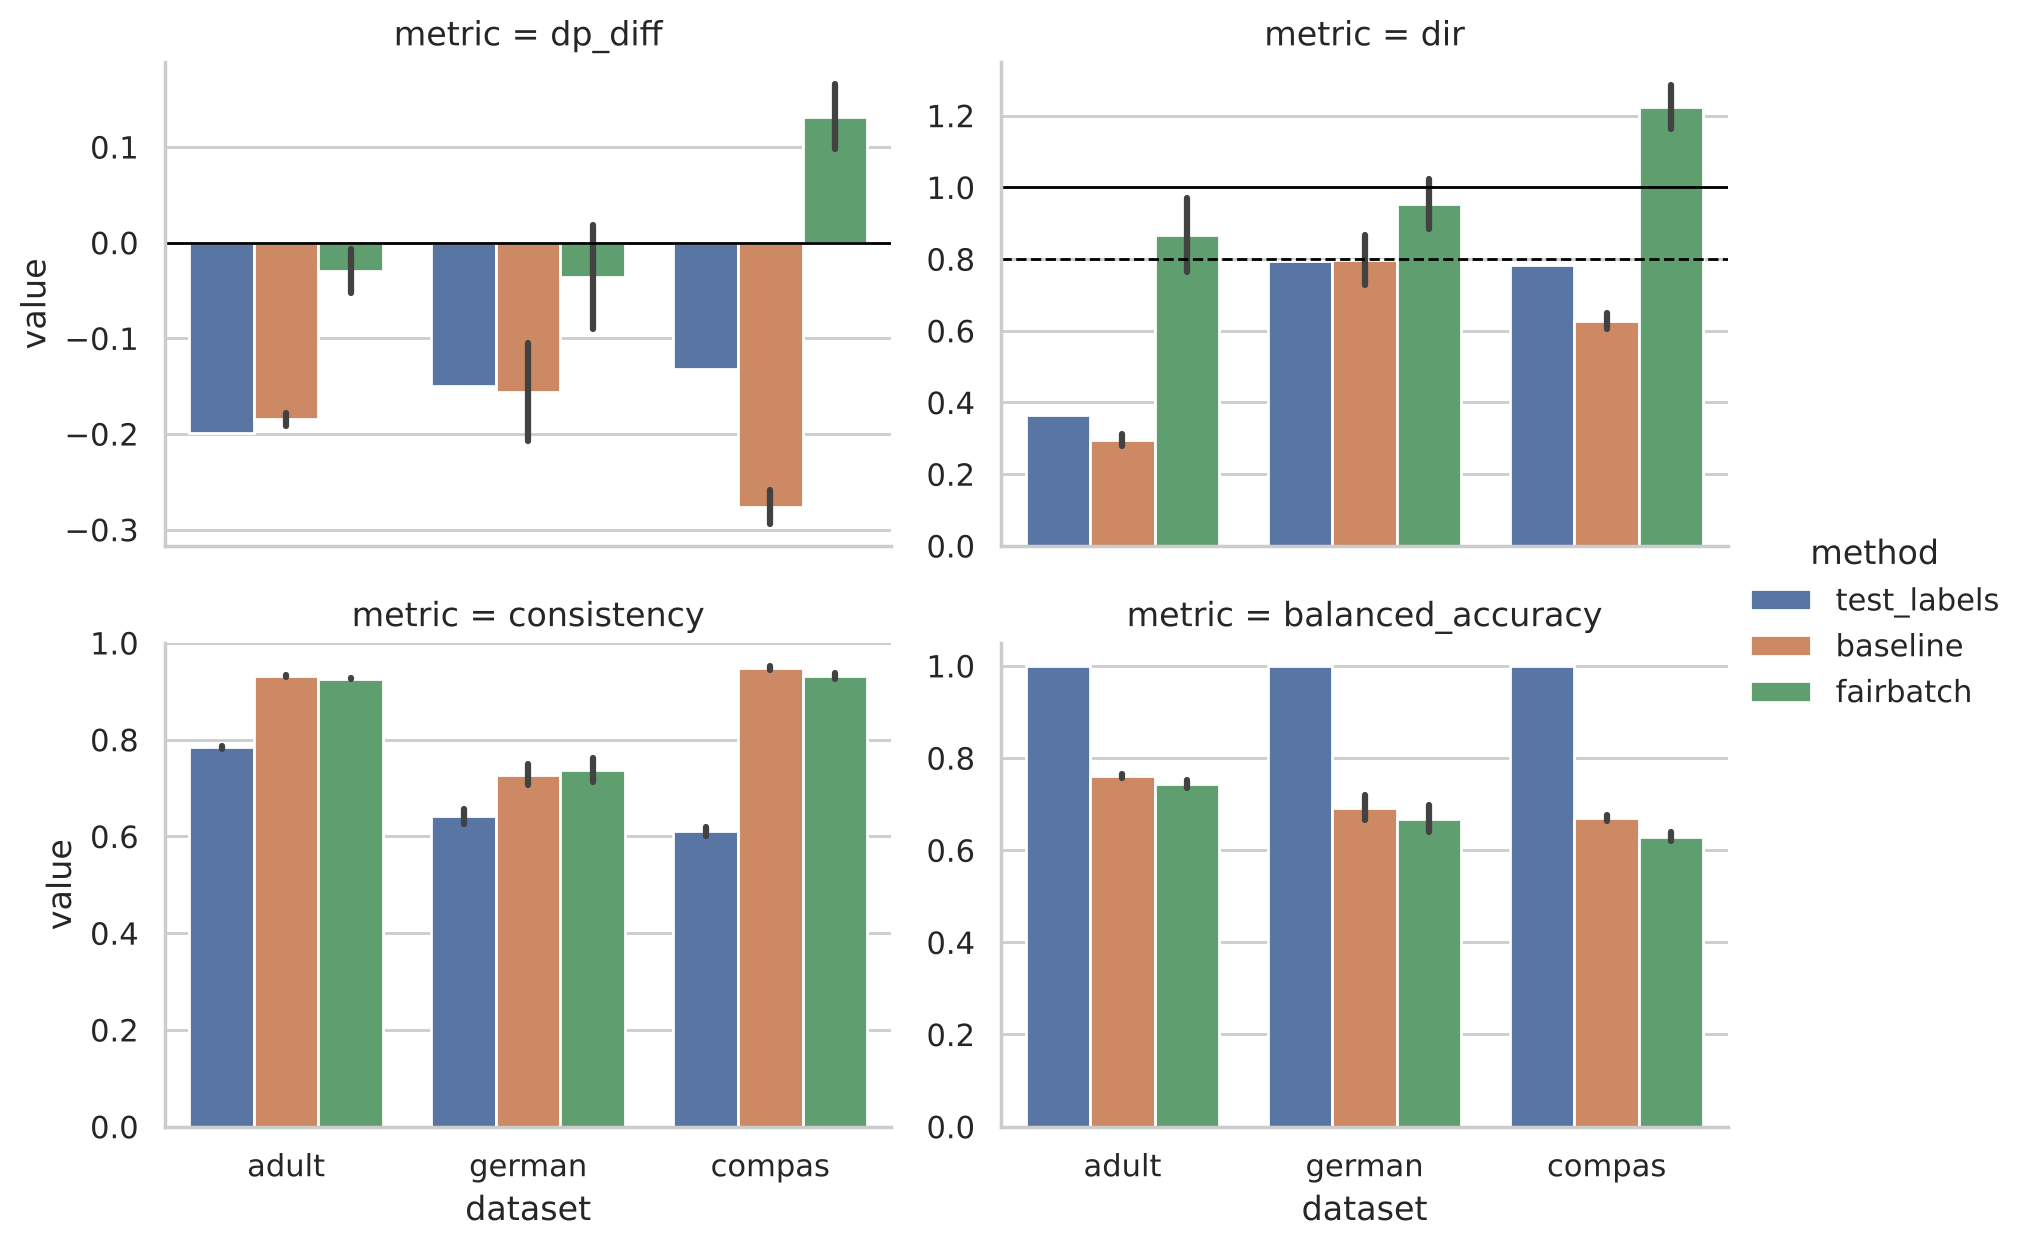

In [7]:
long = main.melt(["dataset", "method"], ["dp_diff", "dir", "consistency", "balanced_accuracy"], "metric")
grid = sns.catplot(long, x="dataset", y="value", hue="method", col="metric", col_wrap=2,
                   order=cfg.DATASETS, hue_order=["test_labels", *ex.METHODS],
                   kind="bar", errorbar="sd", sharey=False, height=3.2, aspect=1.4)
grid.axes_dict["dp_diff"].axhline(0, color="black", lw=1)
grid.axes_dict["dir"].axhline(1, color="black", lw=1)
grid.axes_dict["dir"].axhline(0.8, color="black", lw=1, ls="--");  # four fifths rule

### Paired per seed differences
FairBatch minus baseline on the same split. With 10 seeds the smallest possible two sided Wilcoxon p value is 0.002.

In [8]:
rows = []
for metric in ["dp_diff", "dir", "consistency", "accuracy", "balanced_accuracy"]:
    wide = main.pivot_table(metric, ["dataset", "seed"], "method")
    for name in cfg.DATASETS:
        d = wide.loc[name, "fairbatch"] - wide.loc[name, "baseline"]
        rows.append({"dataset": name, "metric": metric, "mean_diff": d.mean(), "min": d.min(), "max": d.max(),
                     "p_wilcoxon": wilcoxon(d).pvalue})
pd.DataFrame(rows).set_index(["dataset", "metric"]).round(4)

,,mean_diff,min,max,p_wilcoxon
dataset,metric,,,,
adult,dp_diff,0.155,0.122,0.189,0.002
german,dp_diff,0.120,0.021,0.202,0.002
compas,dp_diff,0.408,0.360,0.449,0.002
adult,dir,0.572,0.435,0.745,0.002
german,dir,0.155,0.021,0.270,0.002
compas,dir,0.597,0.513,0.667,0.002
adult,consistency,-0.006,-0.008,-0.003,0.002
german,consistency,0.011,-0.007,0.027,0.027
compas,consistency,-0.017,-0.026,-0.006,0.002


## 5. Lambda trajectories
`lambda1` is the share of the positive examples drawn from group z = 1, `lambda2` the same for the negative examples. They start at the group shares in the data and move by `alpha` once per epoch, clipped to [0, 1]. Seed 0.

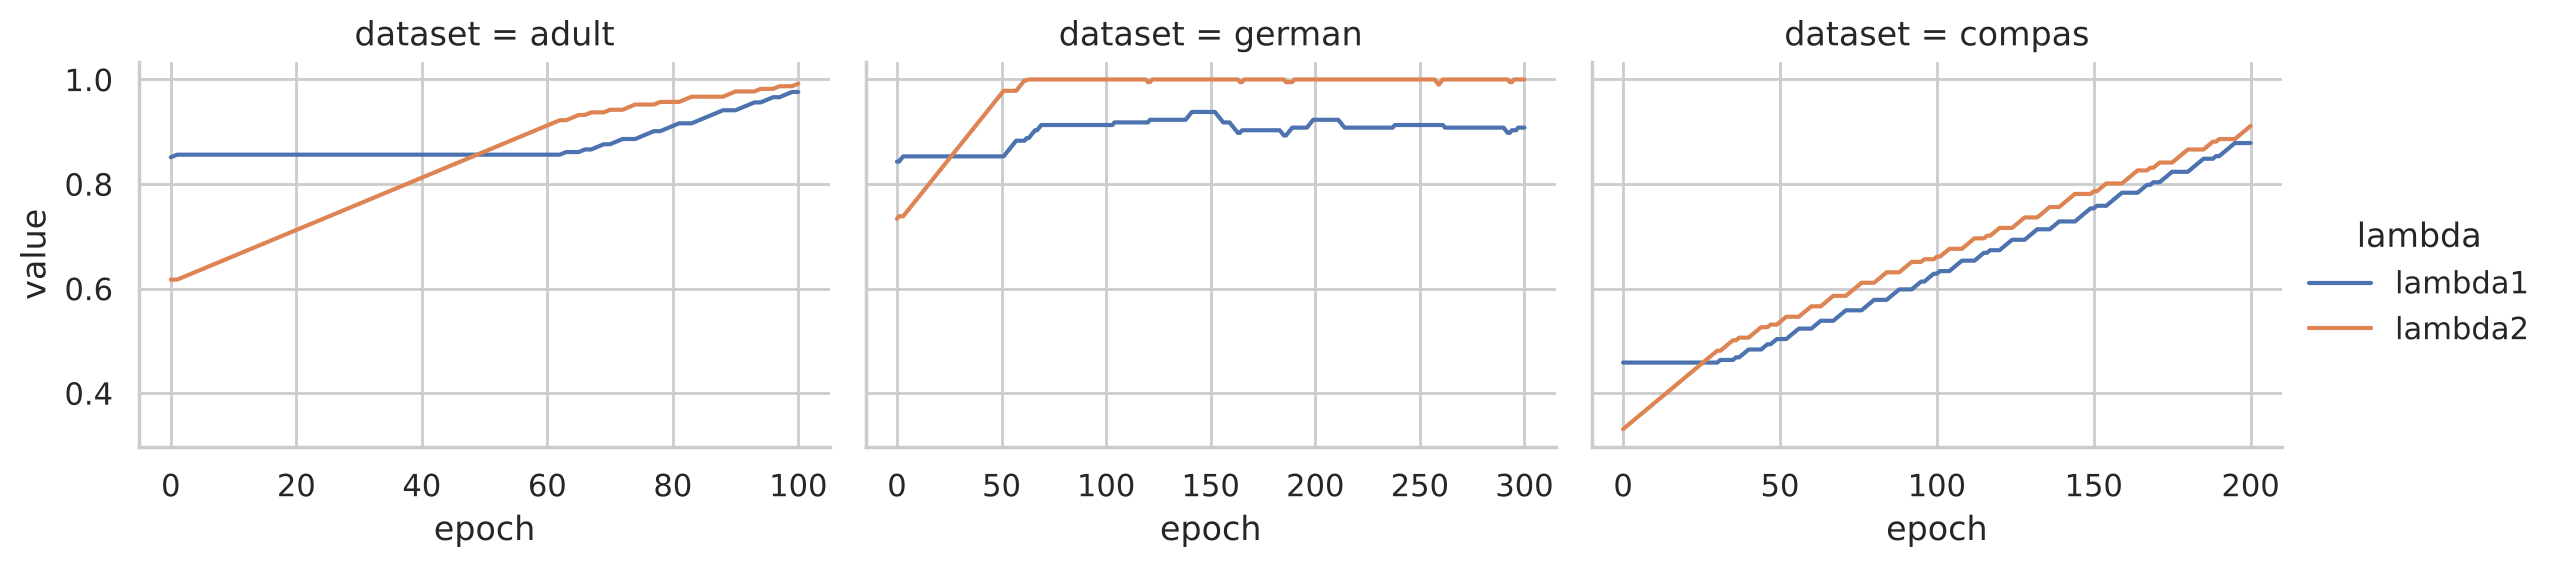

In [9]:
lambdas = ex.lambda_trace()
long = lambdas.melt(["dataset", "epoch"], ["lambda1", "lambda2"], "lambda")
sns.relplot(long, x="epoch", y="value", hue="lambda", col="dataset", col_order=cfg.DATASETS,
            kind="line", height=3, aspect=1.3, facet_kws=dict(sharex=False));

## 6. Step size alpha
FairBatch with different `alpha`, 5 seeds each, all other settings as in section 3.

balanced_accuracy                  dir               dp_diff         \
dataset               adult compas german  adult compas german   adult compas   
alpha                                                                           
5.000e-04             0.760  0.664  0.663  0.314  0.900  0.902  -0.177 -0.064   
1.000e-03             0.759  0.651  0.651  0.347  1.127  0.944  -0.163  0.070   
2.500e-03             0.747  0.642  0.653  0.604  1.200  0.912  -0.087  0.113   
5.000e-03             0.749  0.626  0.651  0.854  1.259  0.933  -0.034  0.151   
1.000e-02             0.749  0.638  0.650  0.867  1.115  0.933  -0.031  0.069   
2.000e-02             0.750  0.625  0.657  0.864  1.196  0.913  -0.031  0.120   

                  
dataset   german  
alpha             
5.000e-04 -0.076  
1.000e-03 -0.043  
2.500e-03 -0.067  
5.000e-03 -0.051  
1.000e-02 -0.051  
2.000e-02 -0.066

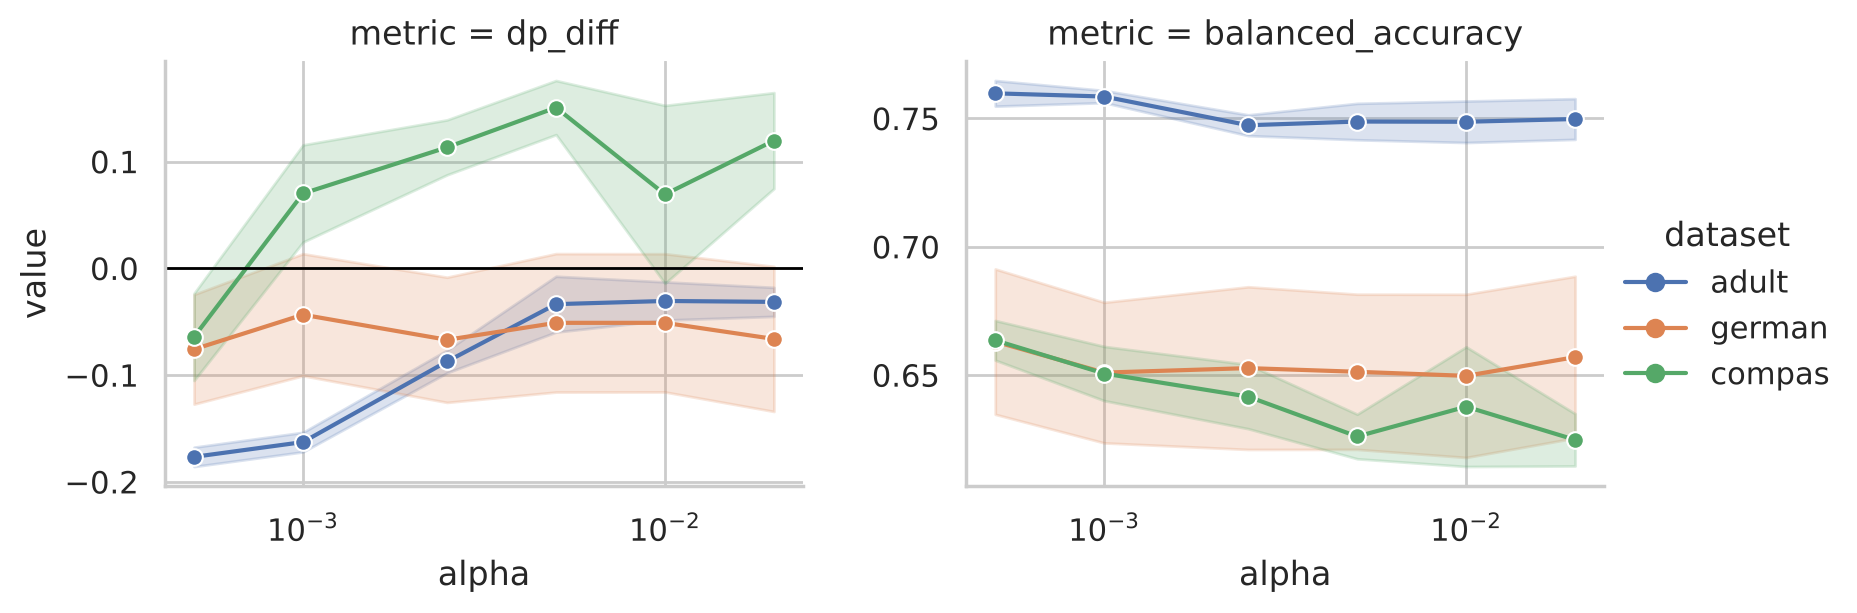

In [10]:
alpha = ex.alpha_experiment()
long = alpha.melt(["dataset", "alpha"], ["dp_diff", "balanced_accuracy"], "metric")
grid = sns.relplot(long, x="alpha", y="value", hue="dataset", col="metric", hue_order=cfg.DATASETS,
                   kind="line", marker="o", errorbar="sd", height=3.2, aspect=1.3, facet_kws=dict(sharey=False))
grid.set(xscale="log")
grid.axes_dict["dp_diff"].axhline(0, color="black", lw=1)
alpha.pivot_table(["dp_diff", "dir", "balanced_accuracy"], "alpha", "dataset")